# Used Car Price Prediction

## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder


import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the Dataset

In [5]:
df = pd.read_csv("D:\\CS\\Data science\\Lec 014\\Task\\used_car_prices.csv")

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

df.head()

Dataset loaded successfully!
Number of rows: 185
Number of columns: 7


,car_id,year,mileage_km,engine_size_L,fuel_type,num_previous_owners,price_usd
0,1,2013,83463.0,2.6,Diesel,1,25487.0
1,2,2019,64287.0,2.0,Diesel,4,25212.0
2,3,2006,203912.0,4.0,Petrol,1,19075.0
3,4,2006,198306.0,1.3,Diesel,3,15510.0
4,5,2008,212852.0,2.9,Petrol,1,19744.0


## 3. Explore the Dataset

In [6]:
display(df.head())
display(df.tail())

,car_id,year,mileage_km,engine_size_L,fuel_type,num_previous_owners,price_usd
0,1,2013,83463.0,2.6,Diesel,1,25487.0
1,2,2019,64287.0,2.0,Diesel,4,25212.0
2,3,2006,203912.0,4.0,Petrol,1,19075.0
3,4,2006,198306.0,1.3,Diesel,3,15510.0
4,5,2008,212852.0,2.9,Petrol,1,19744.0


,car_id,year,mileage_km,engine_size_L,fuel_type,num_previous_owners,price_usd
180,181,2005,217767.0,2.7,Petrol,2,18514.0
181,182,2010,145764.0,NaN,Diesel,2,21171.0
182,183,2011,224949.0,3.3,Petrol,3,20614.0
183,184,2016,61295.0,2.6,Petrol,3,24334.0
184,185,2013,113674.0,3.1,Petrol,1,28053.0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   car_id               185 non-null    int64  
 1   year                 185 non-null    int64  
 2   mileage_km           175 non-null    str    
 3   engine_size_L        177 non-null    float64
 4   fuel_type            181 non-null    str    
 5   num_previous_owners  185 non-null    int64  
 6   price_usd            185 non-null    float64
dtypes: float64(2), int64(3), str(2)
memory usage: 12.6 KB


In [8]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
car_id,185.0,NaN,NaN,NaN,93.0,53.549043,1.0,47.0,93.0,139.0,185.0
year,185.0,NaN,NaN,NaN,2013.632432,4.990755,2005.0,2009.0,2014.0,2018.0,2022.0
mileage_km,175,170,67882.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine_size_L,177.0,NaN,NaN,NaN,2.59096,0.896665,1.0,1.7,2.7,3.4,4.0
fuel_type,181,9,Petrol,87,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_previous_owners,185.0,NaN,NaN,NaN,2.518919,1.063689,1.0,2.0,3.0,3.0,4.0
price_usd,185.0,NaN,NaN,NaN,25870.967568,9264.721405,13270.0,22445.0,25972.0,28164.0,136096.0


In [9]:
print("Columns in the dataset:")
print(df.columns.tolist())

Columns in the dataset:
['car_id', 'year', 'mileage_km', 'engine_size_L', 'fuel_type', 'num_previous_owners', 'price_usd']


In [10]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
car_id                  0
year                    0
mileage_km             10
engine_size_L           8
fuel_type               4
num_previous_owners     0
price_usd               0
dtype: int64


In [11]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


## 4. Data Cleaning

In [12]:
df.columns = df.columns.str.strip()

In [13]:
before_duplicates = len(df)

df = df.drop_duplicates().copy()

print("Duplicate rows removed:", before_duplicates - len(df))
print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows removed: 0
Dataset shape after removing duplicates: (185, 7)


In [14]:
numeric_columns = [
    "year",
    "mileage_km",
    "engine_size_L",
    "num_previous_owners",
    "price_usd"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col].astype("string").str.replace(",", "", regex=False).str.strip(),
            errors="coerce"
        )

print(df[numeric_columns].dtypes)

year                     Int64
mileage_km             Float64
engine_size_L          Float64
num_previous_owners      Int64
price_usd              Float64
dtype: object


In [15]:
df["fuel_type"] = (
    df["fuel_type"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

# Standardize common fuel type labels
fuel_mapping = {
    "petrol": "Petrol",
    "gasoline": "Petrol",
    "diesel": "Diesel",
    "hybrid": "Hybrid",
    "electric": "Electric",
    "ev": "Electric"
}

df["fuel_type"] = df["fuel_type"].replace(fuel_mapping)

print("Fuel type categories:")
print(df["fuel_type"].value_counts(dropna=False))

Fuel type categories:
fuel_type
Petrol    95
Diesel    65
Hybrid    21
<NA>       4
Name: count, dtype: int64[pyarrow]


In [16]:
current_year = pd.Timestamp.now().year

invalid_conditions = (
    (df["year"] < 1886) |
    (df["year"] > current_year) |
    (df["mileage_km"] < 0) |
    (df["engine_size_L"] <= 0) |
    (df["num_previous_owners"] < 0) |
    (df["price_usd"] <= 0)
)

print("Rows containing invalid values:", invalid_conditions.sum())

df.loc[invalid_conditions, [
    "year",
    "mileage_km",
    "engine_size_L",
    "num_previous_owners",
    "price_usd"
]].head()

Rows containing invalid values: 1


,year,mileage_km,engine_size_L,num_previous_owners,price_usd
102,2017,-5000.0,1.3,2,24857.0


In [17]:
df.loc[
    (df["year"] < 1886) | (df["year"] > current_year),
    "year"
] = np.nan

df.loc[df["mileage_km"] < 0, "mileage_km"] = np.nan

df.loc[df["engine_size_L"] <= 0, "engine_size_L"] = np.nan

df.loc[df["num_previous_owners"] < 0, "num_previous_owners"] = np.nan

df.loc[df["price_usd"] <= 0, "price_usd"] = np.nan

In [18]:
numeric_features = [
    "year",
    "mileage_km",
    "engine_size_L",
    "num_previous_owners"
]

for col in numeric_features:
    df[col] = df[col].fillna(df[col].median())

if df["fuel_type"].notna().any():
    df["fuel_type"] = df["fuel_type"].fillna(
        df["fuel_type"].mode()[0]
    )
else:
    df["fuel_type"] = df["fuel_type"].fillna("Unknown")

# The target cannot be imputed for supervised learning
df = df.dropna(subset=["price_usd"]).copy()

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape after cleaning:", df.shape)

Missing values after cleaning:
car_id                 0
year                   0
mileage_km             0
engine_size_L          0
fuel_type              0
num_previous_owners    0
price_usd              0
dtype: int64

Dataset shape after cleaning: (185, 7)


## 5. Outlier Detection

In [19]:
Q1 = df["price_usd"].quantile(0.25)
Q3 = df["price_usd"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["price_usd"] < lower_bound) |
    (df["price_usd"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of potential price outliers:", len(outliers))

display(outliers)

Lower bound: 13866.5
Upper bound: 36742.5
Number of potential price outliers: 3


,car_id,year,mileage_km,engine_size_L,fuel_type,num_previous_owners,price_usd
56,57,2022,18881.0,3.3,Hybrid,1,36937.0
130,131,2012,211566.0,1.4,Petrol,4,136096.0
143,144,2007,115198.0,1.3,Petrol,2,13270.0


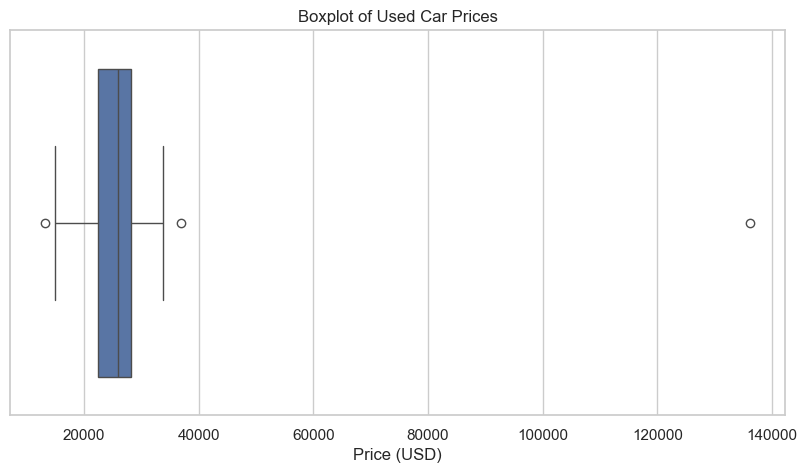

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["price_usd"])

plt.title("Boxplot of Used Car Prices")
plt.xlabel("Price (USD)")

plt.show()

## 6. Exploratory Data Analysis (EDA)

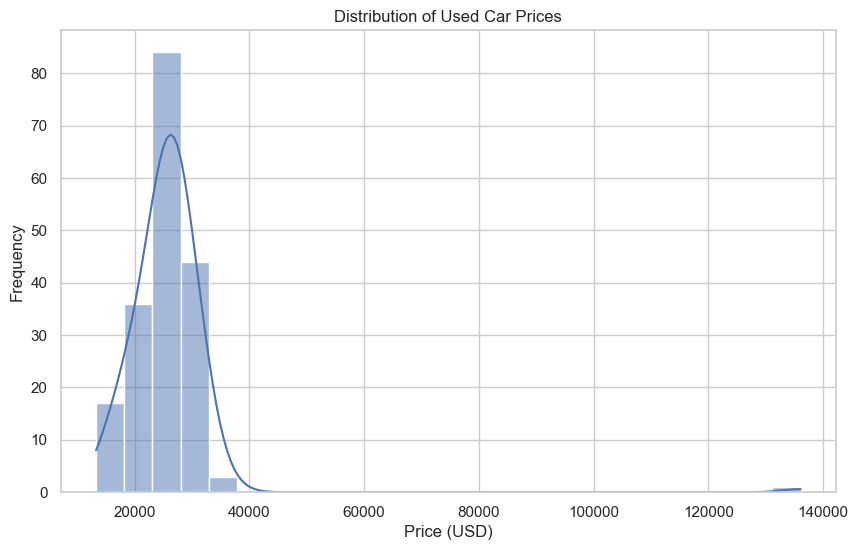

In [21]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="price_usd",
    bins=25,
    kde=True
)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Frequency")

plt.show()

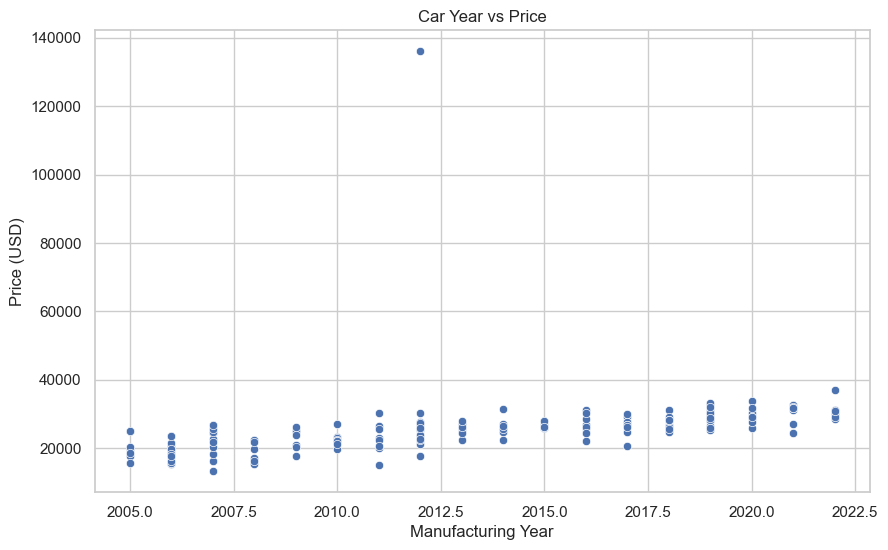

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="year",
    y="price_usd"
)

plt.title("Car Year vs Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Price (USD)")

plt.show()

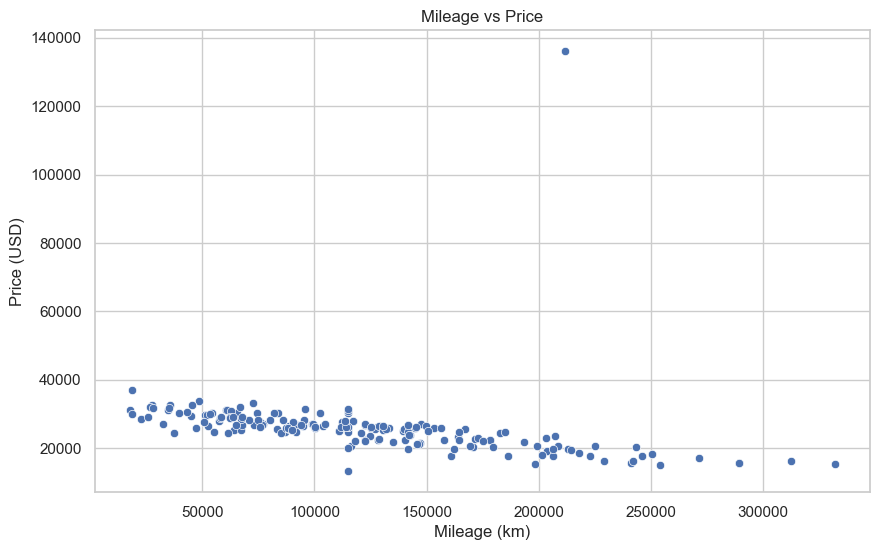

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="mileage_km",
    y="price_usd"
)

plt.title("Mileage vs Price")
plt.xlabel("Mileage (km)")
plt.ylabel("Price (USD)")

plt.show()

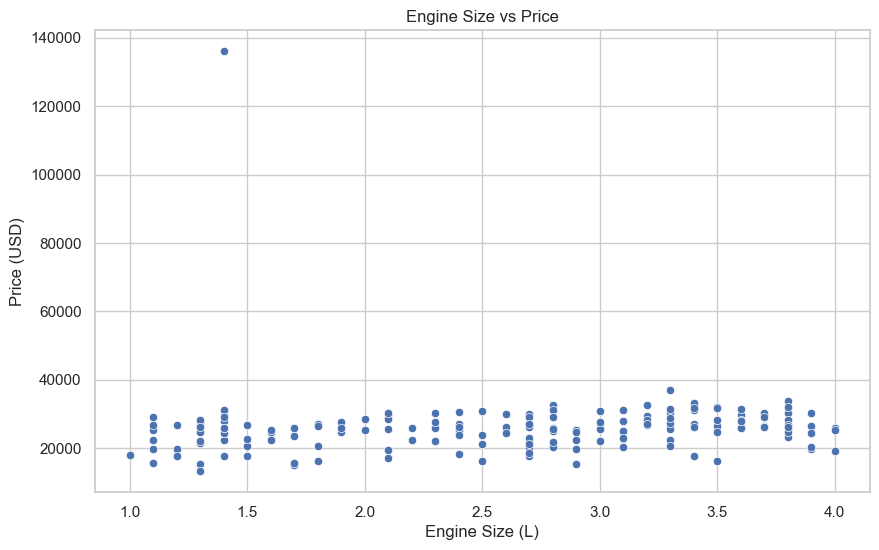

In [24]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="engine_size_L",
    y="price_usd"
)

plt.title("Engine Size vs Price")
plt.xlabel("Engine Size (L)")
plt.ylabel("Price (USD)")

plt.show()

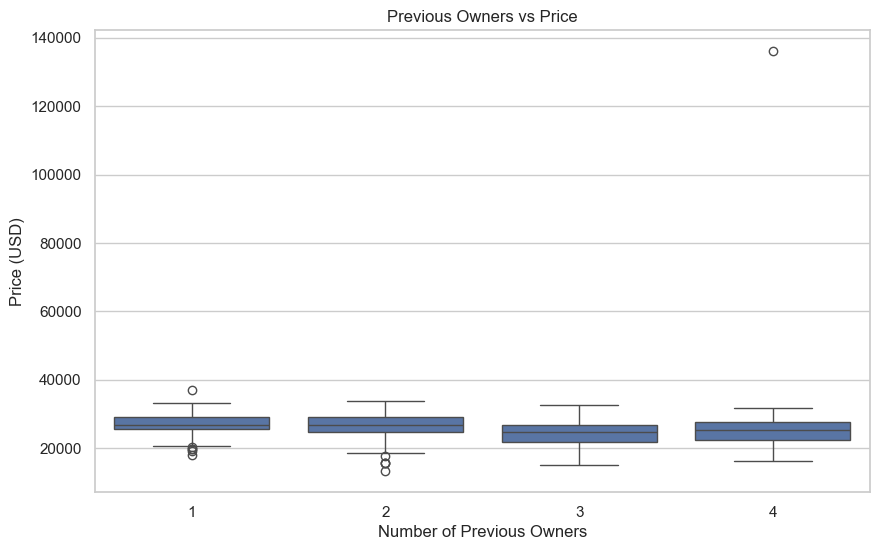

In [25]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="num_previous_owners",
    y="price_usd"
)

plt.title("Previous Owners vs Price")
plt.xlabel("Number of Previous Owners")
plt.ylabel("Price (USD)")

plt.show()

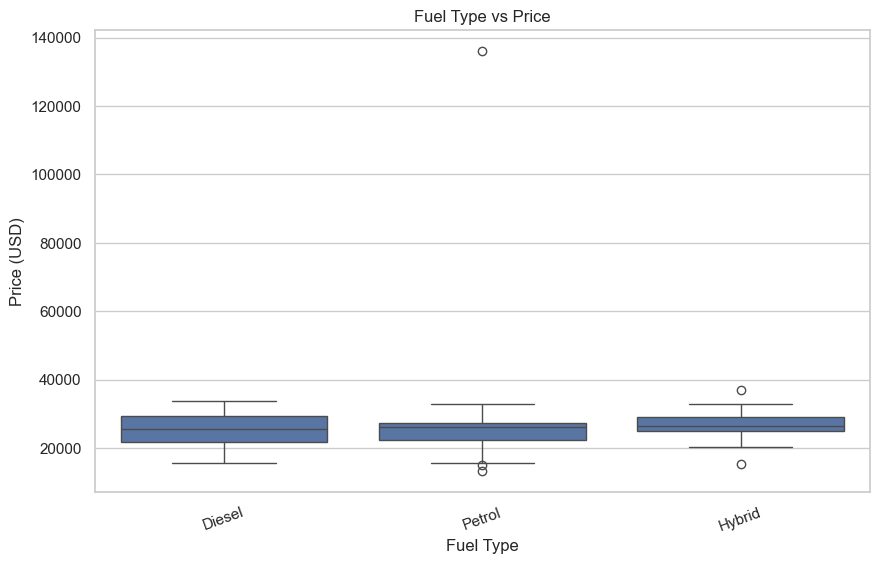

In [26]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="fuel_type",
    y="price_usd"
)

plt.title("Fuel Type vs Price")
plt.xlabel("Fuel Type")
plt.ylabel("Price (USD)")

plt.xticks(rotation=20)

plt.show()

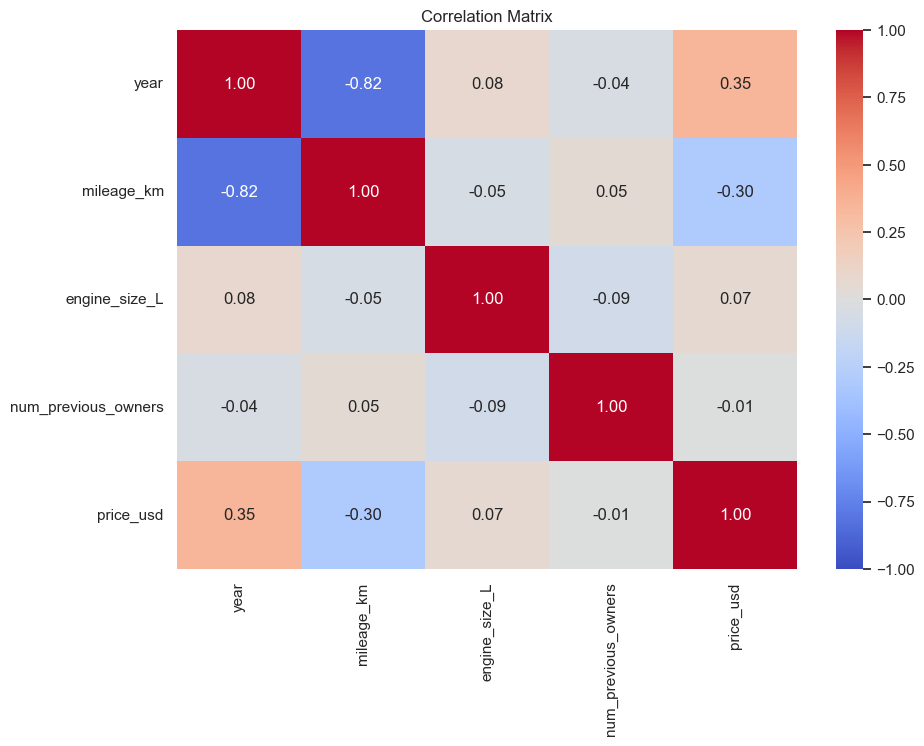

In [27]:
correlation_columns = [
    "year",
    "mileage_km",
    "engine_size_L",
    "num_previous_owners",
    "price_usd"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")

plt.show()

## 7. Prepare Data for Modeling

In [28]:
features = [
    "year",
    "mileage_km",
    "engine_size_L",
    "fuel_type",
    "num_previous_owners"
]

target = "price_usd"

X = df[features].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (148, 5)
Testing features shape: (37, 5)
Training target shape: (148,)
Testing target shape: (37,)


In [ ]:
numeric_features = [
    "year",
    "mileage_km",
    "engine_size_L",
    "num_previous_owners"
]

categorical_features = ["fuel_type"]

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 8. Train the Linear Regression Model

In [30]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


## 9. Make Predictions

In [31]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

display(results.head(10))

,Actual Price,Predicted Price
0,26760.0,27540.137207
1,27159.0,29521.763576
2,30986.0,30057.928599
3,30225.0,25599.183457
4,29219.0,29802.513291
5,33798.0,28644.547569
6,23567.0,19847.511924
7,17645.0,23509.047750
8,22421.0,24742.774386
9,30297.0,25059.248301


## 10. Evaluate Model Performance

In [32]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-" * 35)
print(f"MAE:  ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Model Evaluation Results
-----------------------------------
MAE:  $2,301.14
RMSE: $2,972.31
R² Score: 0.6023


## 11. Actual vs Predicted Prices

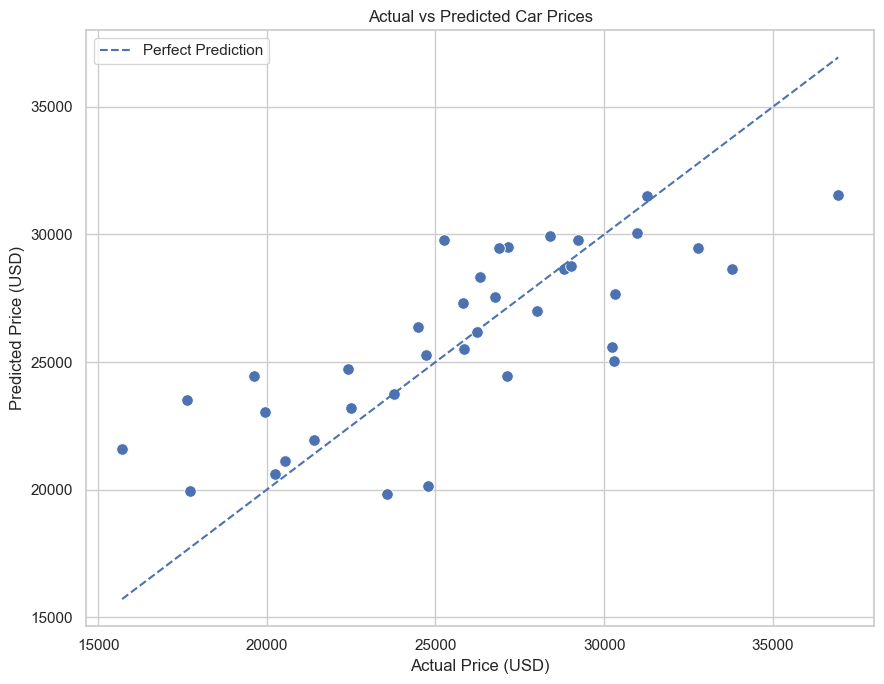

In [33]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    s=70
)

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Car Prices")
plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")

plt.legend()
plt.tight_layout()

plt.show()

## 12. Analyze Model Coefficients

In [34]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

coefficients = model.named_steps["regressor"].coef_

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df["Absolute Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

display(coefficient_df)

,Feature,Coefficient,Absolute Coefficient
4,categorical__fuel_type_Diesel,-1295.993709,1295.993709
5,categorical__fuel_type_Hybrid,691.366327,691.366327
0,numeric__year,668.964533,668.964533
6,categorical__fuel_type_Petrol,604.627382,604.627382
3,numeric__num_previous_owners,340.343930,340.343930
2,numeric__engine_size_L,49.276833,49.276833
1,numeric__mileage_km,0.002088,0.002088
